# Лабораторна робота 5. Метод ліктя. Кластеризація даних

**Виконала:** Сєднєва Уляна, група 4-10
**Варіант:** 19
**Репозиторій GitHub:** https://github.com/UlyanaSedneva/LB5.git

In [1]:
# Підключення бібліотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

pd.set_option('display.float_format', lambda x: f'{x:.3f}')
RANDOM_STATE = 19   # варіант 19 - для відтворюваності результатів

---
# Завдання 1. Кластеризація датасету Ірис

In [2]:
# Завантаження датасету та перші 5 рядків
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
df_iris['species'] = df_iris['target'].map(dict(enumerate(iris.target_names)))
print('Розмір датасету:', df_iris.shape)
df_iris.head()

Розмір датасету: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.100,3.500,1.400,0.200,0,setosa
1,4.900,3.000,1.400,0.200,0,setosa
2,4.700,3.200,1.300,0.200,0,setosa
3,4.600,3.100,1.500,0.200,0,setosa
4,5.000,3.600,1.400,0.200,0,setosa


In [3]:
# Для кластеризації беремо лише 4 числові ознаки (без справжнього виду квітки - кластеризація навчається без учителя).
# KMeans рахує відстані, тому ознаки масштабуємо: інакше довжина пелюстки (1-7 см)
# переважала б ширину (0.1-2.5 см) лише через більший розмах значень.
X_iris = df_iris[iris.feature_names]
print(X_iris.describe().loc[['mean', 'std', 'min', 'max']])
X_iris_s = StandardScaler().fit_transform(X_iris)

      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean              5.843             3.057              3.758             1.199
std               0.828             0.436              1.765             0.762
min               4.300             2.000              1.000             0.100
max               7.900             4.400              6.900             2.500


## Метод ліктя

Для кожного K рахуємо **інерцію** — суму квадратів відстаней точок до центрів їхніх кластерів. Інерція завжди спадає зі зростанням K. Оптимальне K — «лікоть», тобто точка, після якої спад різко сповільнюється.

,K,Інерція,"Спад інерції, %"
0,1,600.000,NaN
1,2,222.362,62.900
2,3,139.820,37.100
3,4,114.097,18.400
4,5,90.927,20.300
5,6,80.679,11.300
6,7,72.057,10.700
7,8,63.661,11.700
8,9,55.074,13.500
9,10,47.351,14.000


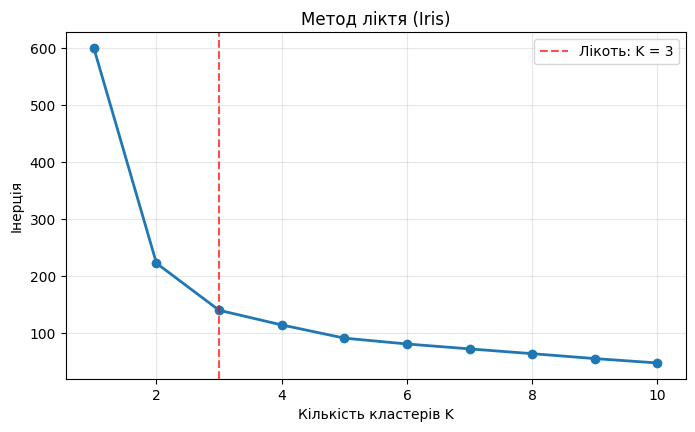

In [4]:
K_range = range(1, 11)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_iris_s).inertia_ for k in K_range]

elbow = pd.DataFrame({'K': list(K_range), 'Інерція': inertia})
elbow['Спад інерції, %'] = (-elbow['Інерція'].pct_change() * 100).round(1)
display(elbow)

plt.figure(figsize=(8, 4.5))
plt.plot(K_range, inertia, 'o-', lw=2)
plt.axvline(3, color='red', ls='--', alpha=0.7, label='Лікоть: K = 3')
plt.xlabel('Кількість кластерів K'); plt.ylabel('Інерція')
plt.title('Метод ліктя (Iris)'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Метод силуетів

**Коефіцієнт силуету** показує, наскільки точка ближча до свого кластера, ніж до сусіднього. Він змінюється від −1 до 1, і що він вищий, то краще розділені кластери. Оптимальне K відповідає максимуму середнього силуету.

,2,3,4,5,6,7,8,9,10
Силует,0.582,0.460,0.383,0.342,0.327,0.331,0.343,0.339,0.345


Максимальний силует: K = 2 (0.582); для K = 3: 0.460


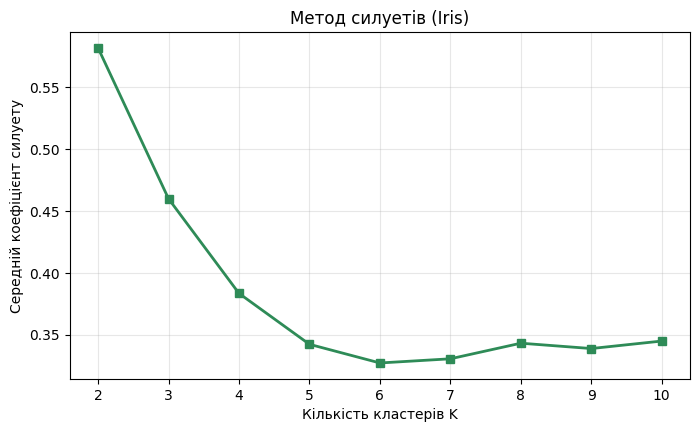

In [5]:
sil = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_iris_s)
    sil[k] = silhouette_score(X_iris_s, labels)
sil = pd.Series(sil, name='Силует')
display(sil.to_frame().T)
print(f'Максимальний силует: K = {sil.idxmax()} ({sil.max():.3f}); для K = 3: {sil[3]:.3f}')

plt.figure(figsize=(8, 4.5))
plt.plot(sil.index, sil.values, 's-', lw=2, color='seagreen')
plt.xlabel('Кількість кластерів K'); plt.ylabel('Середній коефіцієнт силуету')
plt.title('Метод силуетів (Iris)'); plt.grid(alpha=0.3)
plt.show()

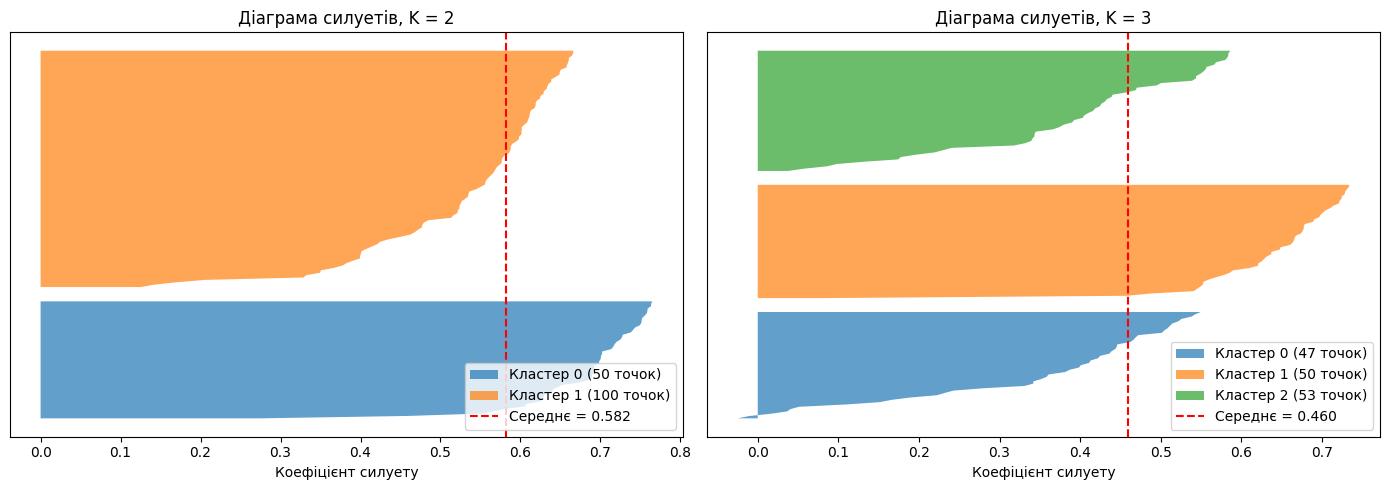

In [6]:
# Діаграми силуетів для K = 2 і K = 3: ширина "ножа" - силует кожної точки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, k in zip(axes, [2, 3]):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_iris_s)
    vals = silhouette_samples(X_iris_s, labels)
    y0 = 0
    for c in range(k):
        v = np.sort(vals[labels == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7, label=f'Кластер {c} ({len(v)} точок)')
        y0 += len(v) + 5
    ax.axvline(vals.mean(), color='red', ls='--', label=f'Середнє = {vals.mean():.3f}')
    ax.set_title(f'Діаграма силуетів, K = {k}'); ax.set_xlabel('Коефіцієнт силуету'); ax.set_yticks([])
    ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## Кластеризація з оптимальним K і візуалізація

In [7]:
# Метод ліктя вказує на K = 3, силует - на K = 2 (детальніше у висновку).
# Остаточно беремо K = 3: на нього вказує лікоть, а силует при K = 3 лишається прийнятним.
K_OPT = 3
km = KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE).fit(X_iris_s)
df_iris['cluster'] = km.labels_

print('Розмір кластерів:', df_iris['cluster'].value_counts().sort_index().to_dict())
print('\nСередні значення ознак у кластерах (см):')
display(df_iris.groupby('cluster')[iris.feature_names].mean())

Розмір кластерів: {0: 47, 1: 50, 2: 53}

Середні значення ознак у кластерах (см):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cluster,,,,
0,6.781,3.096,5.511,1.972
1,5.006,3.428,1.462,0.246
2,5.802,2.674,4.370,1.413


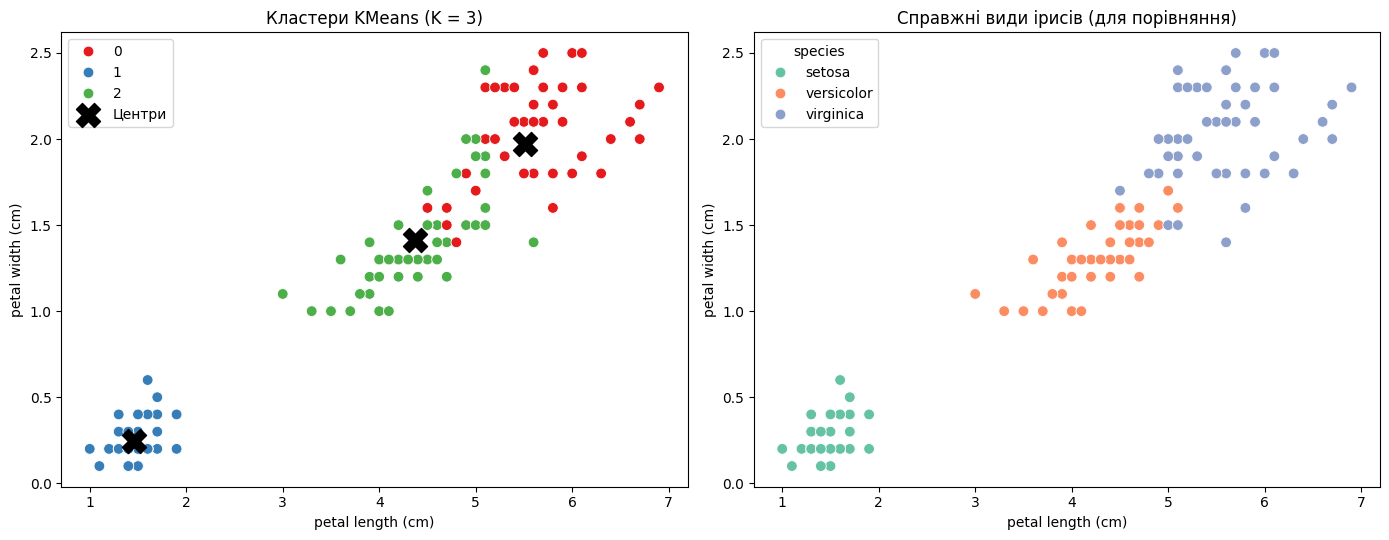

Дві головні компоненти зберігають 95.8 % інформації


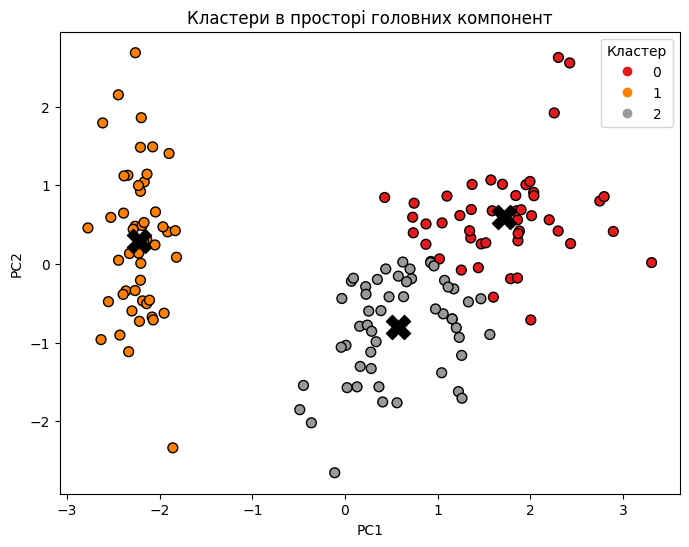

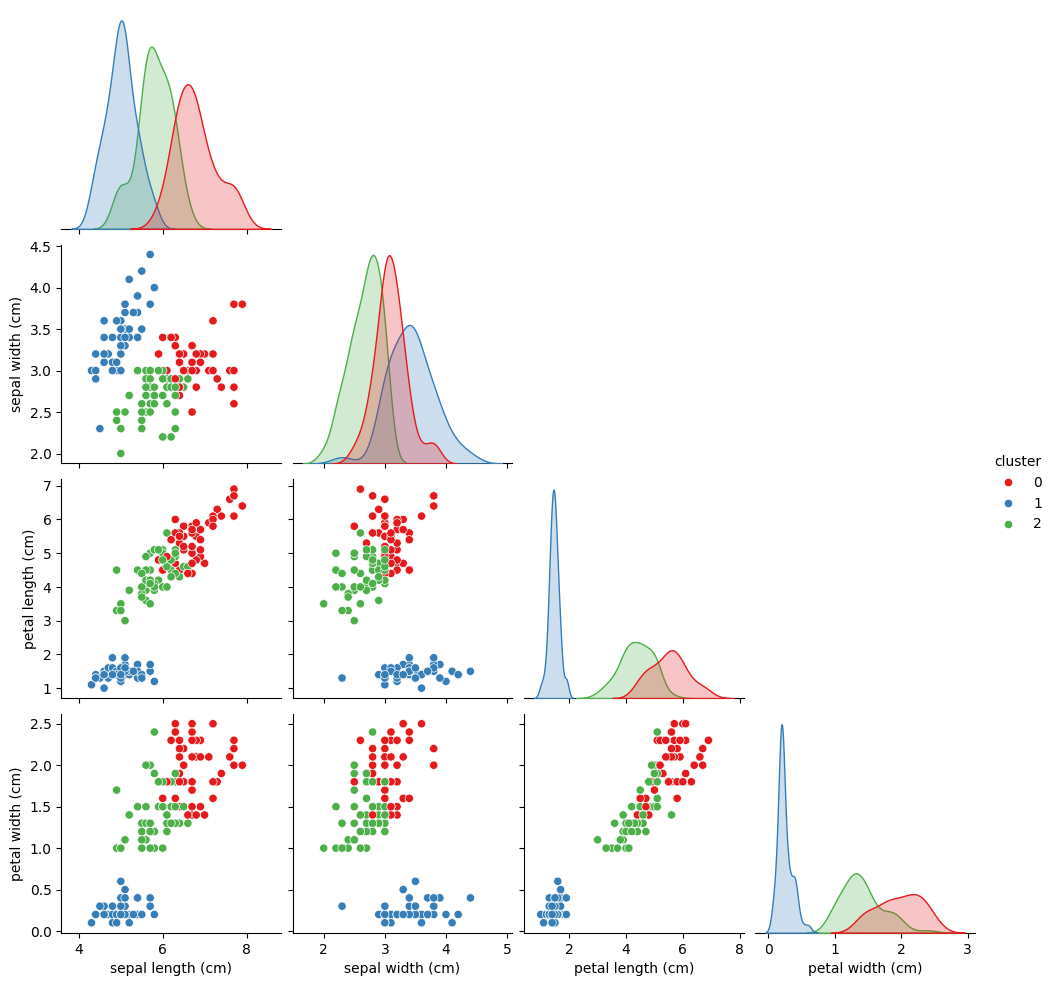

In [8]:
# Візуалізація 1: дві найінформативніші ознаки (довжина і ширина пелюстки)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
centers = StandardScaler().fit(X_iris).inverse_transform(km.cluster_centers_)
sns.scatterplot(data=df_iris, x='petal length (cm)', y='petal width (cm)', hue='cluster',
                palette='Set1', s=60, ax=axes[0])
axes[0].scatter(centers[:, 2], centers[:, 3], marker='X', s=300, c='black', label='Центри')
axes[0].set_title(f'Кластери KMeans (K = {K_OPT})'); axes[0].legend()

sns.scatterplot(data=df_iris, x='petal length (cm)', y='petal width (cm)', hue='species',
                palette='Set2', s=60, ax=axes[1])
axes[1].set_title('Справжні види ірисів (для порівняння)')
plt.tight_layout(); plt.show()

# Візуалізація 2: усі 4 ознаки, стиснуті до 2 головних компонент (PCA)
pca = PCA(n_components=2).fit(X_iris_s)
pc = pca.transform(X_iris_s)
print(f'Дві головні компоненти зберігають {pca.explained_variance_ratio_.sum() * 100:.1f} % інформації')
plt.figure(figsize=(8, 6))
sc = plt.scatter(pc[:, 0], pc[:, 1], c=km.labels_, cmap='Set1', s=50, edgecolor='k')
c_pc = pca.transform(km.cluster_centers_)
plt.scatter(c_pc[:, 0], c_pc[:, 1], marker='X', s=300, c='black', label='Центри')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Кластери в просторі головних компонент')
plt.legend(*sc.legend_elements(), title='Кластер', loc='upper right')
plt.show()

# Попарні діаграми всіх ознак
sns.pairplot(df_iris[iris.feature_names + ['cluster']], hue='cluster', palette='Set1', corner=True)
plt.show()

In [9]:
# Порівняння кластерів зі справжніми видами (види не використовувались під час кластеризації)
ct = pd.crosstab(df_iris['species'], df_iris['cluster'], rownames=['Справжній вид'], colnames=['Кластер'])
display(ct)
ari = adjusted_rand_score(df_iris['target'], df_iris['cluster'])
matched = ct.max(axis=1).sum()
print(f'Збіг кластерів з видами: {matched} з {len(df_iris)} квіток ({matched / len(df_iris) * 100:.1f} %), ARI = {ari:.3f}')

Кластер,0,1,2
Справжній вид,,,
setosa,0,50,0
versicolor,11,0,39
virginica,36,0,14


Збіг кластерів з видами: 125 з 150 квіток (83.3 %), ARI = 0.620


### Висновок до завдання 1

Датасет Ірис містить 150 квіток з 4 числовими ознаками: довжиною та шириною чашолистка і пелюстки. Перед кластеризацією ознаки стандартизовано, бо метод KMeans спирається на відстані, і ознаки з більшим розмахом інакше мали б більшу вагу. Справжні види квіток під час кластеризації не використовувалися.

**Метод ліктя.** При переході від 1 до 2 кластерів інерція зменшується на 62,9 %, від 2 до 3 — ще на 37,1 %, а далі лише на 11–20 % на кожному кроці. Отже, «лікоть» графіка припадає на **K = 3**.

**Метод силуетів.** Найвищий середній силует отримано для K = 2 (0,582), для K = 3 він нижчий (0,460), а далі спадає до 0,33–0,35. Методи дали різні відповіді, і це очікуваний результат для ірисів. Вид setosa чітко відокремлений від інших, а versicolor і virginica частково перекриваються. Тому найчіткіший поділ — на два кластери: «setosa» і «решта».

**Остаточний вибір — K = 3.** Його показує метод ліктя, силует при K = 3 залишається прийнятним (0,46), і саме цей поділ розрізняє versicolor та virginica. Розміри кластерів становлять 50, 53 і 47 квіток:
- кластер 1 — квітки з дрібними пелюстками (довжина 1,46 см, ширина 0,25 см);
- кластер 2 — квітки із середніми пелюстками (4,37 / 1,41 см);
- кластер 0 — квітки з найбільшими пелюстками (5,51 / 1,97 см).

На графіках кластери найкраще розділяються за довжиною та шириною пелюстки. У просторі двох головних компонент, які зберігають 95,8 % інформації, кластер setosa лежить окремо, а два інших межують між собою.

**Порівняння зі справжніми видами.** Кластер 1 повністю збігся з видом setosa: усі 50 квіток і жодної помилки. Кластери 0 і 2 відповідають virginica та versicolor, але між ними перемішано 25 квіток. Загалом кластеризація правильно згрупувала 125 зі 150 квіток (83,3 %), скоригований індекс Ренда ARI = 0,62. Отже, метод KMeans без жодної інформації про види відновив природну структуру даних. Помиляється він лише там, де самі види схожі за розмірами.

---
# Завдання 2. Успішність студентів (Student_data.csv)

Датасет містить дані про 2392 студентів: вік, стать, етнічну належність, освіту батьків, час на навчання, кількість пропусків, заняття з репетитором, підтримку батьків, позакласні активності, середній бал `GPA` (0–4) та підсумкову оцінку `GradeClass` (0 — A, 1 — B, 2 — C, 3 — D, 4 — F).

## 1. Попередній аналіз даних

In [10]:
# Завантаження (у Colab файл спочатку завантажують у панель "Файли" або вибирають у вікні нижче)
import glob
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

found = sorted(glob.glob('*Student*.csv'))
if found:
    fname = found[0]
else:
    from google.colab import files
    uploaded = files.upload()          # вибрати Student_data.csv на комп'ютері
    fname = list(uploaded.keys())[0]
students = pd.read_csv(fname)
print('Зчитано файл:', fname)

# Перші 5 рядків
students.head()

Зчитано файл: Student_data.csv


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.834,7,1,2,0,0,1,0,2.929,2.000
1,1002,18,0,0,1,15.409,0,0,1,0,0,0,0,3.043,1.000
2,1003,15,0,2,3,4.211,26,0,2,0,0,0,0,0.113,4.000
3,1004,17,1,0,3,10.029,14,0,3,1,0,0,0,2.054,3.000
4,1005,17,1,0,2,4.672,17,1,3,0,0,0,0,1.288,4.000


In [11]:
# Розмір датасету і типи даних
print('Розмір датасету (рядки, стовпці):', students.shape, '\n')
print(students.dtypes)

Розмір датасету (рядки, стовпці): (2392, 15) 

StudentID              int64
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
GradeClass           float64
dtype: object


In [12]:
# Пропущені значення: при наявності замінюємо середнім за стовпцем
print('Пропущені значення:\n', students.isna().sum())
students = students.fillna(students.mean(numeric_only=True))
print('\nПропусків після заміни:', students.isna().sum().sum())

Пропущені значення:
 StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Пропусків після заміни: 0


In [13]:
# Дублікати: повні рядки і повтори StudentID
print('Повних дублікатів:', students.duplicated().sum())
print('Повторів StudentID:', students['StudentID'].duplicated().sum())
students = students.drop_duplicates().reset_index(drop=True)
print('Розмір після перевірки:', students.shape)

Повних дублікатів: 0
Повторів StudentID: 0
Розмір після перевірки: (2392, 15)


In [14]:
# Описова статистика
students.describe().T

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.000,2196.500,690.655,1001.000,1598.750,2196.500,2794.250,3392.000
Age,2392.000,16.469,1.124,15.000,15.000,16.000,17.000,18.000
Gender,2392.000,0.511,0.500,0.000,0.000,1.000,1.000,1.000
Ethnicity,2392.000,0.878,1.028,0.000,0.000,0.000,2.000,3.000
ParentalEducation,2392.000,1.746,1.000,0.000,1.000,2.000,2.000,4.000
StudyTimeWeekly,2392.000,9.772,5.653,0.001,5.043,9.705,14.408,19.978
Absences,2392.000,14.541,8.467,0.000,7.000,15.000,22.000,29.000
Tutoring,2392.000,0.301,0.459,0.000,0.000,0.000,1.000,1.000
ParentalSupport,2392.000,2.122,1.123,0.000,1.000,2.000,3.000,4.000
Extracurricular,2392.000,0.383,0.486,0.000,0.000,0.000,1.000,1.000


## 2. Яку задачу розв'язуємо?

Ми визначаємо оцінку студента, тобто `GradeClass`. Вона має лише 5 можливих значень (A, B, C, D, F), а не довільне число. Отже, це задача **класифікації** з 5 класами. Якби прогнозували середній бал `GPA` (неперервне число від 0 до 4), це була б задача регресії.

`GPA` не використовуємо як ознаку. Це інша форма тієї самої оцінки, і на практиці вона невідома тоді, коли ми хочемо спрогнозувати оцінку. Його використання було б «підглядом у відповідь» (data leakage): нижче показано, як воно штучно завищує точність. `StudentID` теж не використовуємо, бо це лише номер студента.

Унікальні значення GradeClass: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  Оцінка  Студентів  Частка, %
0      A        107      4.500
1      B        269     11.200
2      C        391     16.300
3      D        414     17.300
4      F       1211     50.600

Кореляція ознак з GradeClass (більше значення = гірша оцінка):
GPA                 -0.783
Absences             0.729
ParentalSupport     -0.137
StudyTimeWeekly     -0.134
Tutoring            -0.112
Extracurricular     -0.070
ParentalEducation    0.041
Music               -0.036
Sports              -0.027
Ethnicity           -0.023
Gender               0.023
Volunteering         0.013
Age                 -0.006
Name: GradeClass, dtype: float64


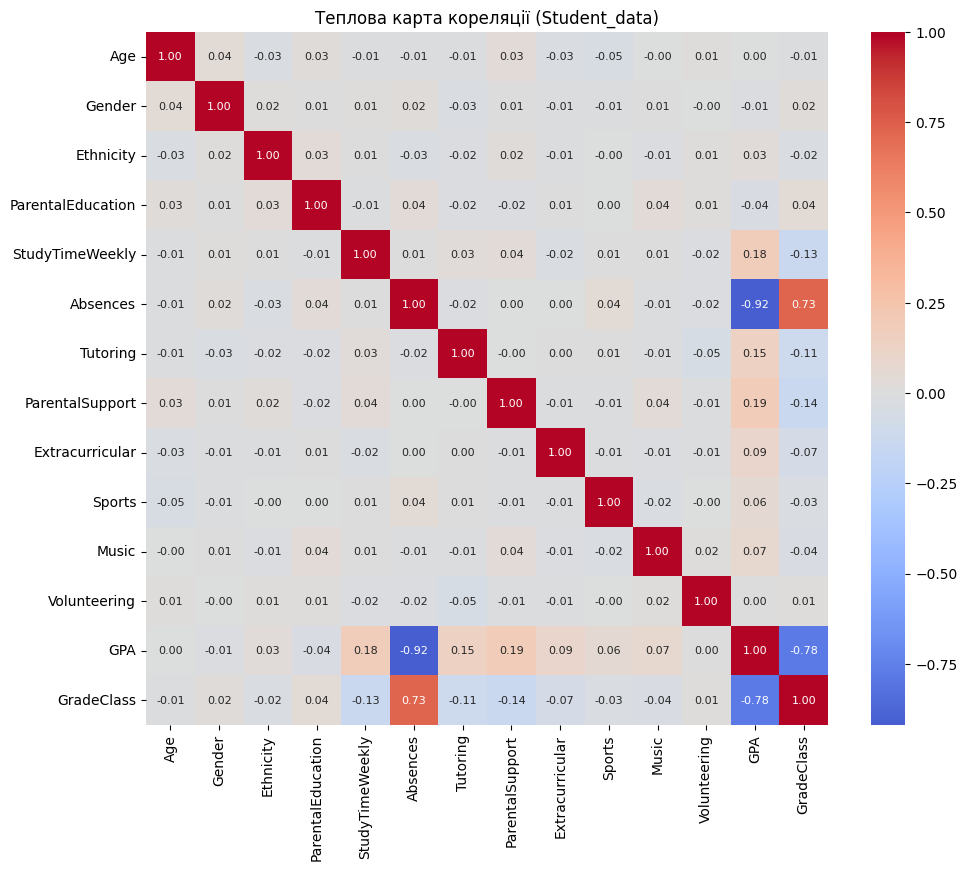

In [15]:
students['GradeClass'] = students['GradeClass'].astype(int)
grade_names = ['A', 'B', 'C', 'D', 'F']
print('Унікальні значення GradeClass:', sorted(students['GradeClass'].unique()))
counts = students['GradeClass'].value_counts().sort_index()
print(pd.DataFrame({'Оцінка': grade_names, 'Студентів': counts.values,
                    'Частка, %': (counts.values / len(students) * 100).round(1)}))

corr_g = students.drop(columns='StudentID').corr()['GradeClass'].drop('GradeClass').sort_values(key=abs, ascending=False)
print('\nКореляція ознак з GradeClass (більше значення = гірша оцінка):')
print(corr_g.round(3))

plt.figure(figsize=(11, 9))
sns.heatmap(students.drop(columns='StudentID').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Теплова карта кореляції (Student_data)')
plt.show()

## 3. Три моделі класифікації і підбір оптимальних параметрів (GridSearchCV)

In [16]:
features_s = [c for c in students.columns if c not in ('StudentID', 'GPA', 'GradeClass')]
X_s = students[features_s]
y_s = students['GradeClass']
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(X_s, y_s, test_size=0.2, stratify=y_s, random_state=RANDOM_STATE)
print('Ознаки:', features_s)
print('Навчальна вибірка:', X_tr_s.shape, ' Тестова вибірка:', X_te_s.shape)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches_s = {
    'Логістична регресія': GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}, cv=cv5, scoring='accuracy', n_jobs=-1),
    'Випадковий ліс': GridSearchCV(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [200], 'max_depth': [5, 10, None], 'min_samples_leaf': [1, 5]},
        cv=cv5, scoring='accuracy', n_jobs=-1),
    'Градієнтний бустинг': GridSearchCV(
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]},
        cv=cv5, scoring='accuracy', n_jobs=-1),
}
for name, gs in searches_s.items():
    gs.fit(X_tr_s, y_tr_s)
    print(f'{name}:\n   найкращі параметри: {gs.best_params_}\n   accuracy на крос-валідації: {gs.best_score_:.4f}')

Ознаки: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']
Навчальна вибірка: (1913, 12)  Тестова вибірка: (479, 12)
Логістична регресія:
   найкращі параметри: {'logisticregression__C': 100}
   accuracy на крос-валідації: 0.7266
Випадковий ліс:
   найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
   accuracy на крос-валідації: 0.7135
Градієнтний бустинг:
   найкращі параметри: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
   accuracy на крос-валідації: 0.7208


## 4. Оцінка моделей

Логістична регресія: accuracy = 0.7056
              precision    recall  f1-score   support

           A      0.000     0.000     0.000        21
           B      0.479     0.426     0.451        54
           C      0.505     0.628     0.560        78
           D      0.586     0.410     0.482        83
           F      0.847     0.955     0.897       243

    accuracy                          0.706       479
   macro avg      0.483     0.484     0.478       479
weighted avg      0.667     0.706     0.681       479

Випадковий ліс: accuracy = 0.7077
              precision    recall  f1-score   support

           A      1.000     0.095     0.174        21
           B      0.467     0.389     0.424        54
           C      0.522     0.615     0.565        78
           D      0.586     0.494     0.536        83
           F      0.841     0.934     0.885       243

    accuracy                          0.708       479
   macro avg      0.683     0.506     0.517       479
weig

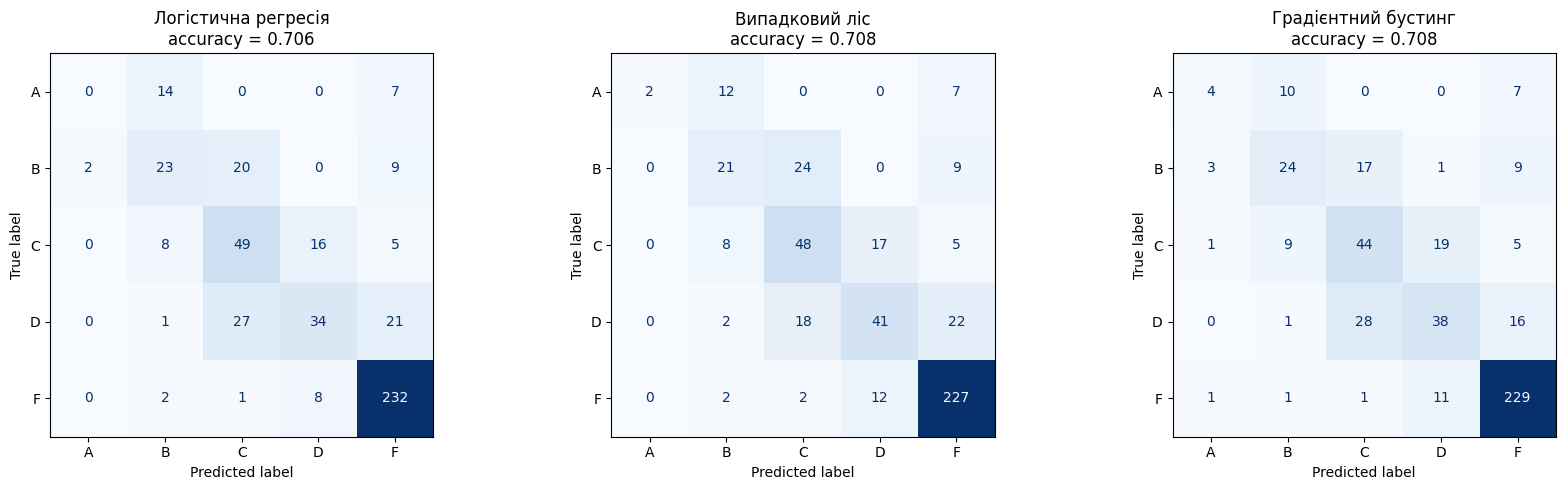

,Accuracy,F1 (macro),F1 (weighted),CV accuracy
Градієнтний бустинг,0.708,0.535,0.695,0.721
Випадковий ліс,0.708,0.517,0.689,0.714
Логістична регресія,0.706,0.478,0.681,0.727


Найкраща модель: Градієнтний бустинг (accuracy = 0.708)
Для порівняння: якщо завжди прогнозувати найчастішу оцінку F, accuracy = 0.507


In [17]:
preds_s = {name: gs.best_estimator_.predict(X_te_s) for name, gs in searches_s.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, pred) in zip(axes, preds_s.items()):
    print('=' * 60)
    print(f'{name}: accuracy = {accuracy_score(y_te_s, pred):.4f}')
    print(classification_report(y_te_s, pred, target_names=grade_names, digits=3, zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_te_s, pred), display_labels=grade_names).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\naccuracy = {accuracy_score(y_te_s, pred):.3f}')
plt.tight_layout(); plt.show()

res_s = pd.DataFrame({name: {'Accuracy': accuracy_score(y_te_s, p),
                             'F1 (macro)': f1_score(y_te_s, p, average='macro'),
                             'F1 (weighted)': f1_score(y_te_s, p, average='weighted'),
                             'CV accuracy': searches_s[name].best_score_}
                      for name, p in preds_s.items()}).T.sort_values(['Accuracy', 'F1 (macro)'], ascending=False)   # при рівній accuracy - кращий F1 (macro)
display(res_s)
best_s = res_s.index[0]
print(f"Найкраща модель: {best_s} (accuracy = {res_s.loc[best_s, 'Accuracy']:.3f})")
print(f"Для порівняння: якщо завжди прогнозувати найчастішу оцінку F, accuracy = {(y_te_s == 4).mean():.3f}")

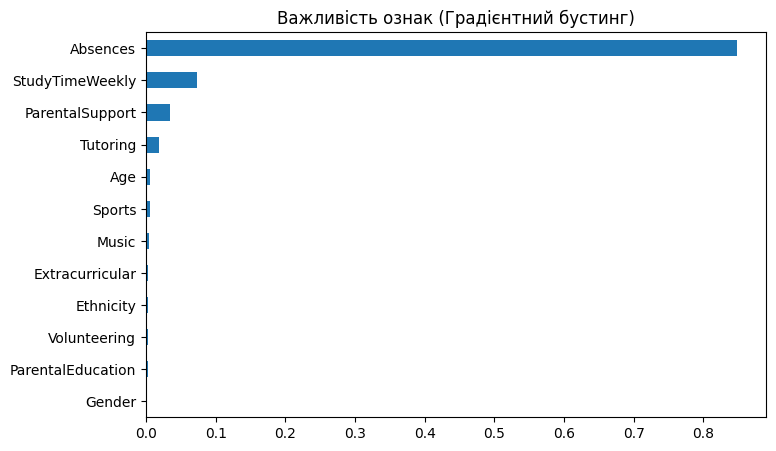

In [18]:
# Які ознаки найважливіші для найкращої моделі (для ансамблів дерев)
best_model_s = searches_s['Градієнтний бустинг'].best_estimator_ if best_s == 'Логістична регресія' else searches_s[best_s].best_estimator_
imp_name = 'Градієнтний бустинг' if best_s == 'Логістична регресія' else best_s
pd.Series(best_model_s.feature_importances_, index=features_s).sort_values().plot.barh(
    figsize=(8, 5), title=f'Важливість ознак ({imp_name})')
plt.show()

In [19]:
# Демонстрація витоку даних: що буде, якщо додати GPA як ознаку
gb_leak = GradientBoostingClassifier(random_state=RANDOM_STATE, **searches_s['Градієнтний бустинг'].best_params_)
X_leak = students[features_s + ['GPA']]
X_tr_l, X_te_l, _, _ = train_test_split(X_leak, y_s, test_size=0.2, stratify=y_s, random_state=RANDOM_STATE)
acc_leak = accuracy_score(y_te_s, gb_leak.fit(X_tr_l, y_tr_s).predict(X_te_l))
print(f"Градієнтний бустинг без GPA: accuracy = {res_s.loc['Градієнтний бустинг', 'Accuracy']:.3f}")
print(f'Градієнтний бустинг з GPA:   accuracy = {acc_leak:.3f}  <- завищено: модель "підглядає" у середній бал')

Градієнтний бустинг без GPA: accuracy = 0.708
Градієнтний бустинг з GPA:   accuracy = 0.927  <- завищено: модель "підглядає" у середній бал


## 5. Кластеризація: метод ліктя і метод силуетів

,Інерція,"Спад інерції, %",Силует
1,7176.000,NaN,NaN
2,3778.520,47.300,0.402
3,2764.485,26.800,0.365
4,1983.435,28.300,0.357
5,1606.389,19.000,0.349
6,1332.758,17.000,0.338
7,1193.451,10.500,0.335
8,1070.363,10.300,0.333
9,957.329,10.600,0.328
10,859.573,10.200,0.323


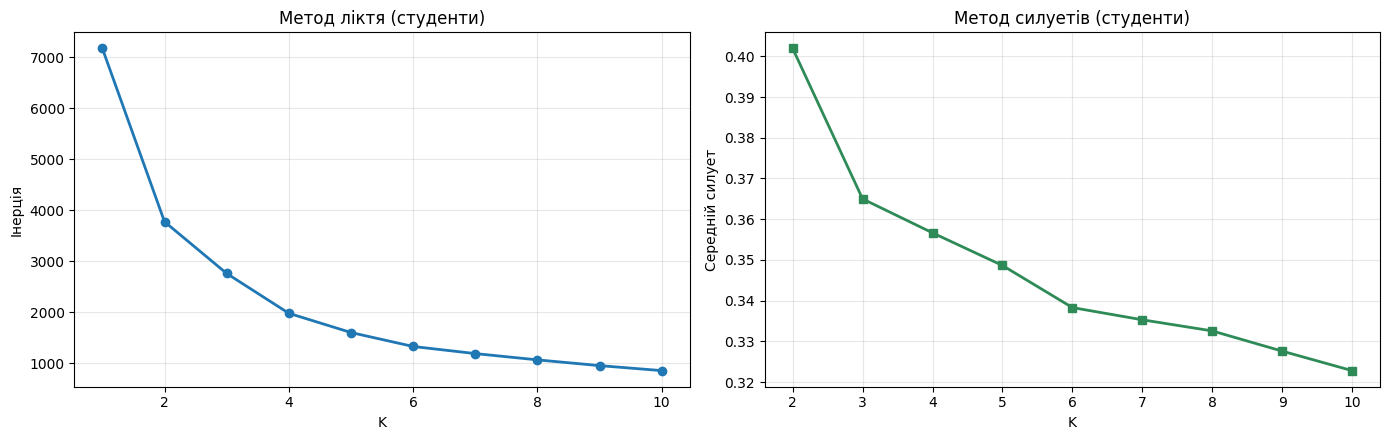

Максимальний силует: K = 2 (0.402)


In [20]:
# Кластеризуємо студентів за трьома неперервними показниками навчання:
# час на навчання за тиждень, кількість пропусків і середній бал.
# (Бінарні ознаки 0/1 та категорії, закодовані числами, для KMeans з евклідовою відстанню не підходять.)
clust_cols = ['StudyTimeWeekly', 'Absences', 'GPA']
X_c = StandardScaler().fit_transform(students[clust_cols])

K_range = range(1, 11)
inertia_s = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_c).inertia_ for k in K_range]
sil_s = pd.Series({k: silhouette_score(X_c, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_c))
                   for k in range(2, 11)})

display(pd.DataFrame({'Інерція': pd.Series(inertia_s, index=K_range),
                      'Спад інерції, %': (-pd.Series(inertia_s, index=K_range).pct_change() * 100).round(1),
                      'Силует': sil_s}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(K_range, inertia_s, 'o-', lw=2)
axes[0].set_xlabel('K'); axes[0].set_ylabel('Інерція'); axes[0].set_title('Метод ліктя (студенти)'); axes[0].grid(alpha=0.3)
axes[1].plot(sil_s.index, sil_s.values, 's-', lw=2, color='seagreen')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Середній силует'); axes[1].set_title('Метод силуетів (студенти)'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Максимальний силует: K = {sil_s.idxmax()} ({sil_s.max():.3f})')

## 6. Візуалізація кластерів

K = 2. Розмір кластерів: {0: 1182, 1: 1210}

Профіль кластерів (середні значення):


,StudyTimeWeekly,Absences,GPA,GradeClass
cluster,,,,
0,10.265,7.292,2.679,2.128
1,9.290,21.623,1.151,3.820


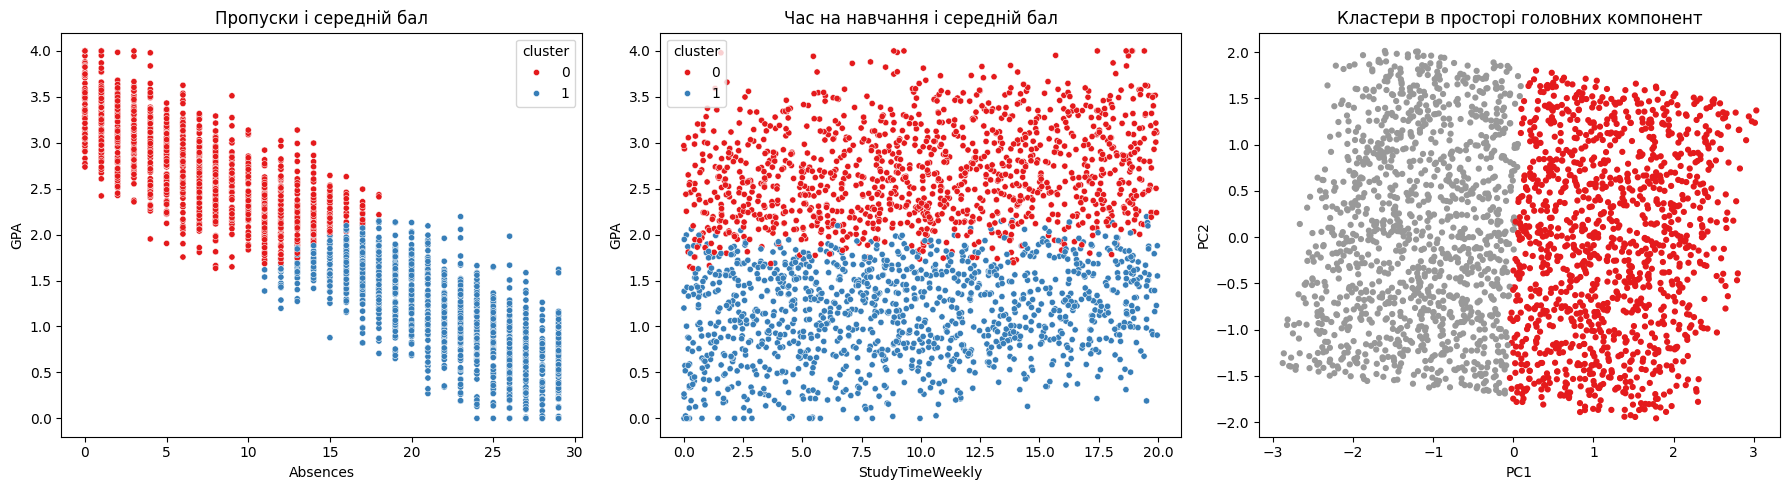

Розподіл оцінок у кожному кластері, %:


GradeClass,A,B,C,D,F
cluster,,,,,
0,7.800,20.500,31.600,31.600,8.600
1,1.200,2.200,1.500,3.400,91.700


In [21]:
K_S = int(sil_s.idxmax())
km_s = KMeans(n_clusters=K_S, n_init=10, random_state=RANDOM_STATE).fit(X_c)
students['cluster'] = km_s.labels_

print(f'K = {K_S}. Розмір кластерів:', students['cluster'].value_counts().sort_index().to_dict())
print('\nПрофіль кластерів (середні значення):')
display(students.groupby('cluster')[clust_cols + ['GradeClass']].mean())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=students, x='Absences', y='GPA', hue='cluster', palette='Set1', s=20, ax=axes[0])
axes[0].set_title('Пропуски і середній бал')
sns.scatterplot(data=students, x='StudyTimeWeekly', y='GPA', hue='cluster', palette='Set1', s=20, ax=axes[1])
axes[1].set_title('Час на навчання і середній бал')
pc_s = PCA(n_components=2).fit_transform(X_c)
axes[2].scatter(pc_s[:, 0], pc_s[:, 1], c=km_s.labels_, cmap='Set1', s=12)
axes[2].set_xlabel('PC1'); axes[2].set_ylabel('PC2'); axes[2].set_title('Кластери в просторі головних компонент')
plt.tight_layout(); plt.show()

ct_s = pd.crosstab(students['cluster'], students['GradeClass'].map(dict(enumerate(grade_names))),
                   normalize='index').mul(100).round(1)[grade_names]
print('Розподіл оцінок у кожному кластері, %:')
display(ct_s)

### Висновок до завдання 2

**Попередній аналіз.** Датасет містить 2392 студентів і 15 стовпців, усі вони числові. Категоріальні ознаки, як-от стать, етнічна належність і освіта батьків, уже закодовано цілими числами. Пропусків і дублікатів немає. У середньому студент навчається 9,8 години на тиждень і має 14,5 пропуску, а середній бал GPA становить 1,91 з 4.

**Тип задачі.** Ми прогнозуємо оцінку `GradeClass`, яка має 5 значень (A–F), тож це задача класифікації. Класи сильно незбалансовані: половина студентів (50,6 %) має оцінку F, а оцінку A — лише 4,5 %. З оцінкою найсильніше пов'язані кількість пропусків (r = 0,73) та середній бал (r = −0,78). Зв'язок з підтримкою батьків, часом на навчання та заняттями з репетитором слабкий (|r| ≈ 0,11–0,14), а решта ознак майже не впливають. Середній бал GPA виключено з ознак, бо це та сама оцінка в іншій формі. З ним точність штучно зростає з 0,708 до 0,927 — це витік даних.

**Моделі.** Параметри підібрано за допомогою GridSearchCV з 5-блочною крос-валідацією:
- логістична регресія: C = 100;
- випадковий ліс: 200 дерев, глибина 10;
- градієнтний бустинг: 200 дерев глибиною 2, learning rate 0,05.

На тестовій вибірці всі три моделі показали майже однакову точність: 0,706–0,708. Це значно краще, ніж просто завжди ставити найчастішу оцінку F (0,507). Найкращою обрано градієнтний бустинг: при однаковій з лісом accuracy (0,708) він має найвищий F1 (macro), тобто 0,535.

Найважливіша ознака — кількість пропусків: на неї припадає 85 % важливості в бустингу. Далі з великим відривом іде час на навчання (7 %). Двійки (F) моделі розпізнають дуже добре: recall становить 0,93–0,96. А от відмінників (A) моделі майже не знаходять, бо їх лише 21 у тестовій вибірці. Звідси й низький F1 (macro). Отже, за наявними ознаками можна надійно передбачити, чи провалить студент предмет, але точну високу оцінку передбачити важко.

**Кластеризація.** Студентів кластеризовано за трьома неперервними показниками: часом на навчання, кількістю пропусків і середнім балом. Метод ліктя не дає чіткого «згину». При переході від 1 до 2 кластерів інерція зменшується найсильніше (на 47 %), а далі спадає поступово, на 27, 28 і 19 %. Найвищий силует отримано для K = 2 (0,402), тому оптимальним обрано **K = 2**.

Кластери вийшли майже однакового розміру (1182 і 1210 студентів) і мають чіткий зміст:
- **кластер 0** — «відповідальні» студенти: 7,3 пропуску, GPA 2,68, лише 8,6 % оцінок F;
- **кластер 1** — «проблемні» студенти: 21,6 пропуску, GPA 1,15, 91,7 % оцінок F.

Час на навчання в кластерах майже однаковий (10,3 та 9,3 години). Отже, кластеризація без жодної інформації про оцінки фактично розділила студентів на тих, хто встигає, і тих, хто не встигає. Головним чинником цього поділу, як і в моделях класифікації, є кількість пропусків.